In [2]:
import pandas as pd
import numpy as  np
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
wine_df = pd.read_csv("wineB.csv")

In [4]:
wine_df.head()

,Cultivar,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280/OD315_of_diluted_wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [5]:
wine_array = wine_df.values

In [7]:
from sklearn.model_selection import train_test_split

X = wine_array[ : , 1: ]
y = wine_array[ : , 0 ]

In [8]:
X_train , X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2 , random_state = 1)

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score


In [21]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [22]:
print(accuracy_score(y_test, predictions))
print(confusion_matrix(y_test,predictions))

0.8888888888888888
[[13  1  0]
 [ 1 12  0]
 [ 0  2  7]]


In [18]:
#we just remove the traget variable for PCA, we are extracting the variance from the independant variables

wine_no_label = wine_df.drop(columns=["Cultivar"])



In [23]:
pca = PCA().fit(wine_no_label)

Text(0, 0.5, 'cumulative explained variance')

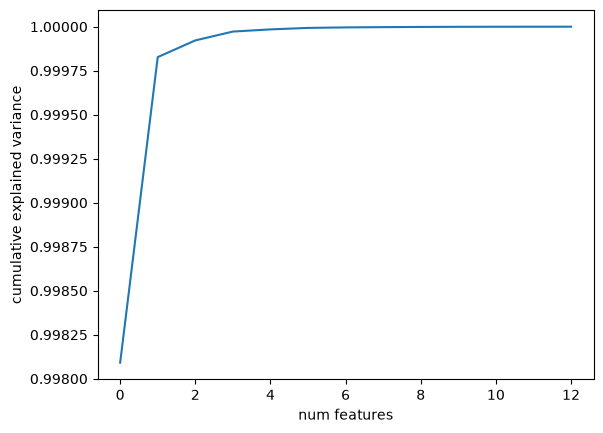

In [26]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("num features")
plt.ylabel("cumulative explained variance")

In [ ]:
#the above shows us how many features we need to get close to 100%, 4

In [29]:
pca = PCA(4)
projected = pca.fit_transform(wine_no_label)

In [30]:
projected.shape

(178, 4)

In [31]:
wine_pca = pd.DataFrame(projected, columns = ["C1", "C2","C3", "C4"])

In [32]:
wine_pca.head()

,C1,C2,C3,C4
0,318.562979,21.492131,-3.130735,0.250114
1,303.097420,-5.364718,-6.822835,0.864035
2,438.061133,-6.537309,1.113223,-0.912411
3,733.240139,0.192729,0.917257,0.541251
4,-11.571428,18.489995,0.554422,-1.360896


In [33]:
wine_pca["Cultivar"] = wine_df["Cultivar"]
wine_pca.head()


,C1,C2,C3,C4,Cultivar
0,318.562979,21.492131,-3.130735,0.250114,1
1,303.097420,-5.364718,-6.822835,0.864035,1
2,438.061133,-6.537309,1.113223,-0.912411,1
3,733.240139,0.192729,0.917257,0.541251,1
4,-11.571428,18.489995,0.554422,-1.360896,1


In [35]:
wine_array=wine_pca.values
X = wine_array[ : , : 4]
y = wine_array[ : , 4 ]

In [37]:
X_train , X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2 , random_state = 1)


In [38]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [39]:
print(accuracy_score(y_test, predictions))
print(confusion_matrix(y_test,predictions))

0.9444444444444444
[[13  1  0]
 [ 0 13  0]
 [ 1  0  8]]
